# Scalability Experiment: Hybrid Graph WaveNet vs GC-LSTM

Notebook ini digunakan untuk mengevaluasi **scalability model terhadap perubahan jumlah node** pada dataset Final64.

Eksperimen membandingkan dua model:

1. **Hybrid Graph WaveNet (Hybrid GWN)**  
   Menggunakan kombinasi fixed geographic graph dan adaptive graph yang dipelajari selama training.

2. **GC-LSTM Fair**  
   Digunakan sebagai baseline pembanding dengan graph propagation yang diikuti pemodelan temporal menggunakan Long Short-Term Memory (LSTM).

## Tujuan Eksperimen

Eksperimen ini bertujuan untuk melihat bagaimana perubahan jumlah node memengaruhi:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Training time
- Inference time per sample
- Number of model parameters

## Skala Graph

Dataset Final64 memiliki 64 corridor. Pengujian dilakukan menggunakan empat ukuran graph:

| Scale | Number of Nodes |
|---|---:|
| Small | 8 |
| Medium | 16 |
| Large | 32 |
| Full | 64 |

Subset dibuat secara **nested**:

`8 nodes ⊂ 16 nodes ⊂ 32 nodes ⊂ 64 nodes`

Node pusat ditentukan berdasarkan node dengan rata-rata jarak geografis terkecil terhadap seluruh node pada `distance_matrix`. Berdasarkan hasil tersebut, **Kuningan (node 4)** digunakan sebagai center node.

Node kemudian diurutkan berdasarkan jaraknya terhadap center node. Dengan demikian, penambahan jumlah node dilakukan secara bertahap dari area yang lebih dekat menuju cakupan graph yang lebih besar.

## Fixed Graph Construction

Untuk setiap ukuran graph, fixed geographic graph dibangun kembali menggunakan **K-Nearest Neighbors (KNN)** dengan `K = 4`.

Artinya, setiap node dihubungkan secara directed ke empat node terdekat di dalam subset graph yang sedang diuji.

Fixed supports yang digunakan oleh Hybrid Graph WaveNet terdiri dari:

- Forward normalized adjacency
- Reverse normalized adjacency

Adaptive adjacency pada Hybrid Graph WaveNet tetap dipelajari secara otomatis selama proses training sesuai jumlah node pada masing-masing skala.

## Experimental Procedure

Untuk setiap ukuran graph (`8`, `16`, `32`, dan `64` node):

1. Dataset train, validation, dan test disubset berdasarkan node yang digunakan.
2. Fixed geographic graph dibangun kembali menggunakan KNN.
3. Hybrid Graph WaveNet dibangun ulang sesuai jumlah node.
4. GC-LSTM dibangun ulang sesuai jumlah node.
5. Kedua model dilatih dari awal menggunakan konfigurasi training yang konsisten.
6. Model dievaluasi menggunakan MAE dan RMSE.
7. Training time, inference time, dan jumlah parameter dicatat.

Dengan prosedur ini, eksperimen mengevaluasi perubahan performa prediksi dan biaya komputasi ketika ukuran graph meningkat.

In [1]:
from pathlib import Path
import sys
import random
import time

import numpy as np
import pandas as pd
import tensorflow as tf

# ============================================================
# FIND PROJECT ROOT
# ============================================================

HERE = Path.cwd().resolve()

ROOT = None

for candidate in [HERE, *HERE.parents]:
    if (candidate / "data" / "final_64" / "stgnn_train.npz").exists():
        ROOT = candidate
        break

if ROOT is None:
    raise FileNotFoundError("Project root tidak ditemukan.")

print("ROOT:", ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# ============================================================
# PATHS
# ============================================================

DATA_DIR = ROOT / "data" / "final_64"

GRAPH_PATH = ROOT / "outputs" / "final_64" / "fixed_graph" / "fixed_graph_64.npz"

OUTPUT_DIR = ROOT / "outputs" / "final_64" / "scalability"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD DATA
# ============================================================

train = np.load(DATA_DIR / "stgnn_train.npz", allow_pickle=True)

val = np.load(DATA_DIR / "stgnn_val.npz", allow_pickle=True)

test = np.load(DATA_DIR / "stgnn_test.npz", allow_pickle=True)

graph = np.load(GRAPH_PATH, allow_pickle=True)

X_train = train["X"]
y_train = train["y"]
mask_train = train["mask"]

X_val = val["X"]
y_val = val["y"]
mask_val = val["mask"]

X_test = test["X"]
y_test = test["y"]
mask_test = test["mask"]

distance_matrix = graph["distance_matrix"].astype(np.float32)

print("\n=== FINAL64 ===")
print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)
print("Distance:", distance_matrix.shape)

ROOT: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent

=== FINAL64 ===
Train: (415, 12, 64, 1) (415, 3, 64)
Val  : (92, 12, 64, 1) (92, 3, 64)
Test : (93, 12, 64, 1) (93, 3, 64)
Distance: (64, 64)


In [2]:
# ============================================================
# FIXED NESTED NODE SUBSETS
# Center = Kuningan (node 4)
# ============================================================

NODE_ORDER = [
    4,
    1,
    5,
    48,
    16,
    63,
    45,
    22,
    61,
    50,
    6,
    36,
    60,
    41,
    42,
    0,
    18,
    56,
    21,
    19,
    17,
    51,
    11,
    2,
    33,
    13,
    34,
    58,
    54,
    35,
    31,
    40,
    46,
    52,
    44,
    27,
    43,
    14,
    3,
    55,
    57,
    53,
    20,
    24,
    47,
    59,
    37,
    38,
    15,
    7,
    30,
    29,
    23,
    9,
    10,
    32,
    12,
    28,
    39,
    62,
    49,
    25,
    26,
    8,
]

NODE_SUBSETS = {8: NODE_ORDER[:8], 16: NODE_ORDER[:16], 32: NODE_ORDER[:32], 64: NODE_ORDER[:64]}

for n, nodes in NODE_SUBSETS.items():
    print(f"{n:2d} nodes |", nodes)

 8 nodes | [4, 1, 5, 48, 16, 63, 45, 22]
16 nodes | [4, 1, 5, 48, 16, 63, 45, 22, 61, 50, 6, 36, 60, 41, 42, 0]
32 nodes | [4, 1, 5, 48, 16, 63, 45, 22, 61, 50, 6, 36, 60, 41, 42, 0, 18, 56, 21, 19, 17, 51, 11, 2, 33, 13, 34, 58, 54, 35, 31, 40]
64 nodes | [4, 1, 5, 48, 16, 63, 45, 22, 61, 50, 6, 36, 60, 41, 42, 0, 18, 56, 21, 19, 17, 51, 11, 2, 33, 13, 34, 58, 54, 35, 31, 40, 46, 52, 44, 27, 43, 14, 3, 55, 57, 53, 20, 24, 47, 59, 37, 38, 15, 7, 30, 29, 23, 9, 10, 32, 12, 28, 39, 62, 49, 25, 26, 8]


In [3]:
# ============================================================
# SCALABILITY DATA + GRAPH BUILDER
# ============================================================

K_NEIGHBORS = 4


def row_normalize_adjacency(adj):

    adj = np.asarray(adj, dtype=np.float32)

    degree = adj.sum(axis=1)

    degree_inv = np.zeros_like(degree, dtype=np.float32)

    nonzero = degree > 0

    degree_inv[nonzero] = 1.0 / degree[nonzero]

    return (degree_inv[:, None] * adj).astype(np.float32)


def build_subset_knn(nodes, k=4):

    nodes = np.asarray(nodes, dtype=int)

    # distance hanya antar-node
    # yang masuk subset
    D = distance_matrix[np.ix_(nodes, nodes)].copy()

    n = len(nodes)

    A = np.zeros((n, n), dtype=np.float32)

    # jangan pilih diri sendiri
    np.fill_diagonal(D, np.inf)

    for i in range(n):
        nearest = np.argsort(D[i])[: min(k, n - 1)]

        A[i, nearest] = 1.0

    return A


def build_scalability_data(nodes):

    nodes = np.asarray(nodes, dtype=int)

    data = {
        "X_train": X_train[:, :, nodes, :],
        "y_train": y_train[:, :, nodes],
        "mask_train": mask_train[:, :, nodes],
        "X_val": X_val[:, :, nodes, :],
        "y_val": y_val[:, :, nodes],
        "mask_val": mask_val[:, :, nodes],
        "X_test": X_test[:, :, nodes, :],
        "y_test": y_test[:, :, nodes],
        "mask_test": mask_test[:, :, nodes],
    }

    A_directed = build_subset_knn(nodes, k=K_NEIGHBORS)

    A_forward = row_normalize_adjacency(A_directed)

    A_reverse = row_normalize_adjacency(A_directed.T)

    data["A_directed"] = A_directed

    data["fixed_supports"] = [A_forward, A_reverse]

    return data

In [4]:
# ============================================================
# VERIFY ALL SCALES
# ============================================================

for n, nodes in NODE_SUBSETS.items():
    d = build_scalability_data(nodes)

    print("\n" + "=" * 55)
    print(f"SCALABILITY: {n} NODES")
    print("=" * 55)

    print("Train:", d["X_train"].shape, d["y_train"].shape, d["mask_train"].shape)

    print("Val  :", d["X_val"].shape, d["y_val"].shape, d["mask_val"].shape)

    print("Test :", d["X_test"].shape, d["y_test"].shape, d["mask_test"].shape)

    print("Adjacency:", d["A_directed"].shape)

    print("Directed edges:", int(d["A_directed"].sum()))

    print("Forward support:", d["fixed_supports"][0].shape)

    print("Reverse support:", d["fixed_supports"][1].shape)


SCALABILITY: 8 NODES
Train: (415, 12, 8, 1) (415, 3, 8) (415, 3, 8)
Val  : (92, 12, 8, 1) (92, 3, 8) (92, 3, 8)
Test : (93, 12, 8, 1) (93, 3, 8) (93, 3, 8)
Adjacency: (8, 8)
Directed edges: 32
Forward support: (8, 8)
Reverse support: (8, 8)

SCALABILITY: 16 NODES
Train: (415, 12, 16, 1) (415, 3, 16) (415, 3, 16)
Val  : (92, 12, 16, 1) (92, 3, 16) (92, 3, 16)
Test : (93, 12, 16, 1) (93, 3, 16) (93, 3, 16)
Adjacency: (16, 16)
Directed edges: 64
Forward support: (16, 16)
Reverse support: (16, 16)

SCALABILITY: 32 NODES
Train: (415, 12, 32, 1) (415, 3, 32) (415, 3, 32)
Val  : (92, 12, 32, 1) (92, 3, 32) (92, 3, 32)
Test : (93, 12, 32, 1) (93, 3, 32) (93, 3, 32)
Adjacency: (32, 32)
Directed edges: 128
Forward support: (32, 32)
Reverse support: (32, 32)

SCALABILITY: 64 NODES
Train: (415, 12, 64, 1) (415, 3, 64) (415, 3, 64)
Val  : (92, 12, 64, 1) (92, 3, 64) (92, 3, 64)
Test : (93, 12, 64, 1) (93, 3, 64) (93, 3, 64)
Adjacency: (64, 64)
Directed edges: 256
Forward support: (64, 64)
Reverse 

## 5. Dynamic Model Construction

Pada bagian ini, Hybrid Graph WaveNet dan GC-LSTM dibangun secara dinamis sesuai jumlah node pada setiap skala graph.

Konfigurasi utama kedua model dipertahankan sama dengan eksperimen Final64 sebelumnya. Perubahan hanya dilakukan pada dimensi yang bergantung pada jumlah node.

### Hybrid Graph WaveNet

Hybrid Graph WaveNet menggunakan:

- dua fixed supports: forward dan reverse geographic adjacency,
- satu adaptive adjacency yang dipelajari selama training,
- 4 temporal blocks,
- 2 layers per block,
- diffusion order = 2,
- residual channels = 32,
- dilation channels = 32,
- skip channels = 256,
- end channels = 512,
- adaptive embedding dimension = 10,
- dropout = 0.3.

### GC-LSTM

GC-LSTM menggunakan:

- graph propagation dengan 32 units,
- flattening fitur seluruh node pada setiap timestep,
- LSTM dengan 64 units,
- dropout = 0.3,
- multi-horizon output untuk t+1, t+3, dan t+6.

Model dibangun ulang untuk setiap ukuran graph agar jumlah parameter dan biaya komputasi dapat berubah secara alami mengikuti jumlah node.

In [5]:
# ============================================================
# DYNAMIC MODEL BUILDERS
# ============================================================

from tensorflow.keras import layers, Model

from streamlit_app.model_loader import GraphWaveNetModel

# Graph WaveNet configuration
NUM_HORIZONS = 3
INPUT_STEPS = 12

GW_RESIDUAL_CHANNELS = 32
GW_DILATION_CHANNELS = 32
GW_SKIP_CHANNELS = 256
GW_END_CHANNELS = 512
GW_BLOCKS = 4
GW_LAYERS = 2
GW_KERNEL_SIZE = 2
GW_DIFFUSION_ORDER = 2
GW_ADAPTIVE_EMBED_DIM = 10
GW_DROPOUT = 0.3

# GC-LSTM configuration
GC_UNITS = 32
LSTM_UNITS = 64
GC_DROPOUT = 0.3


# ============================================================
# GC-LSTM GRAPH PROPAGATION
# ============================================================


class ScalabilityGraphPropagation(layers.Layer):
    def __init__(self, adjacency, units, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.proj = layers.Dense(units, activation="relu")

    def call(self, x):

        x = tf.einsum("ij,btjf->btif", self.adjacency, x)

        return self.proj(x)


# ============================================================
# GC-LSTM BUILDER
# ============================================================


def build_gclstm_scalability(num_nodes, adjacency):

    inputs = layers.Input(shape=(INPUT_STEPS, num_nodes, 1), name="traffic_input")

    x = ScalabilityGraphPropagation(adjacency, GC_UNITS, name="graph_propagation")(inputs)

    x = layers.Reshape((INPUT_STEPS, num_nodes * GC_UNITS), name="flatten_graph_features")(x)

    x = layers.LSTM(LSTM_UNITS, return_sequences=False, name="temporal_lstm")(x)

    x = layers.Dropout(GC_DROPOUT, name="dropout")(x)

    x = layers.Dense(NUM_HORIZONS * num_nodes, name="forecast_dense")(x)

    outputs = layers.Reshape((NUM_HORIZONS, num_nodes), name="forecast_output")(x)

    return Model(inputs=inputs, outputs=outputs, name=f"GC_LSTM_{num_nodes}")


# ============================================================
# HYBRID GRAPH WAVENET BUILDER
# ============================================================


def build_hybrid_scalability(num_nodes, fixed_supports):

    model = GraphWaveNetModel(
        mode="hybrid",
        fixed_supports=fixed_supports,
        num_nodes=num_nodes,
        num_horizons=NUM_HORIZONS,
        name=f"Hybrid_GWN_{num_nodes}",
    )

    # Build model using dummy input
    dummy = tf.zeros((1, INPUT_STEPS, num_nodes, 1), dtype=tf.float32)

    _ = model(dummy, training=False)

    return model

In [6]:
# ============================================================
# SMOKE TEST — 8 NODES
# ============================================================

tf.keras.backend.clear_session()

nodes_8 = NODE_SUBSETS[8]

data_8 = build_scalability_data(nodes_8)

# GC-LSTM uses normalized forward adjacency
A_gc_8 = data_8["fixed_supports"][0]

gclstm_8 = build_gclstm_scalability(num_nodes=8, adjacency=A_gc_8)

hybrid_8 = build_hybrid_scalability(num_nodes=8, fixed_supports=data_8["fixed_supports"])

sample_x = tf.convert_to_tensor(data_8["X_train"][:2], dtype=tf.float32)

gc_out = gclstm_8(sample_x, training=False)

hybrid_out = hybrid_8(sample_x, training=False)

print("=== 8-NODE MODEL AUDIT ===")

print("\nInput:")
print(sample_x.shape)

print("\nGC-LSTM:")
print("Output :", gc_out.shape)
print("Params :", gclstm_8.count_params())

print("\nHybrid GWN:")
print("Output :", hybrid_out.shape)
print("Params :", hybrid_8.count_params())

=== 8-NODE MODEL AUDIT ===

Input:
(2, 12, 8, 1)

GC-LSTM:
Output : (2, 3, 8)
Params : 83800

Hybrid GWN:
Output : (2, 3, 8)
Params : 292835


## 6. Training Configuration

Sebelum menjalankan seluruh eksperimen scalability, dilakukan pengujian awal pada graph berukuran **8 node**.

Kedua model dilatih menggunakan konfigurasi yang konsisten dengan eksperimen sebelumnya:

- Seed = 42
- Optimizer = Adam
- Learning rate = 0.001
- Batch size = 32
- Maximum epochs = 300
- Early stopping patience = 25
- ReduceLROnPlateau patience = 8
- ReduceLROnPlateau factor = 0.5
- Minimum learning rate = 0.00001

Training menggunakan `mask` untuk memastikan hanya target yang valid yang berkontribusi terhadap loss.

Tahap 8-node ini digunakan sebagai validasi awal sebelum prosedur yang sama diterapkan pada graph 16, 32, dan 64 node.

In [7]:
# ============================================================
# TRAINING CONFIGURATION
# ============================================================

SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 32
MAX_EPOCHS = 300

EARLY_STOPPING_PATIENCE = 25
LR_PATIENCE = 8
LR_FACTOR = 0.5
MIN_LR = 1e-5


def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def elementwise_squared_error(y_true, y_pred):
    return tf.square(y_true - y_pred)


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []
        self.training_start = time.perf_counter()

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(time.perf_counter() - self.epoch_start)

    def on_train_end(self, logs=None):
        self.total_training_time = time.perf_counter() - self.training_start


def make_callbacks():

    timer = EpochTimer()

    callbacks = [
        timer,
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=LR_FACTOR, patience=LR_PATIENCE, min_lr=MIN_LR, verbose=1
        ),
    ]

    return callbacks, timer


def compile_model(model):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=elementwise_squared_error,
    )

    return model

## 7. Eight-Node Training Test

Hybrid Graph WaveNet dan GC-LSTM terlebih dahulu dilatih pada subset 8 node.

Selain nilai validation loss, waktu training juga dicatat untuk memperoleh:

- total training time,
- rata-rata waktu per epoch,
- jumlah epoch yang dijalankan,
- best epoch berdasarkan minimum validation loss.

Jika kedua model dapat menyelesaikan training dan menghasilkan prediksi dengan dimensi yang benar, konfigurasi ini selanjutnya digunakan untuk eksperimen scalability pada seluruh ukuran graph.

In [8]:
# ============================================================
# TRAIN GC-LSTM — 8 NODES
# ============================================================

tf.keras.backend.clear_session()
set_seed(SEED)

data_8 = build_scalability_data(NODE_SUBSETS[8])

gclstm_8 = build_gclstm_scalability(num_nodes=8, adjacency=data_8["fixed_supports"][0])

gclstm_8 = compile_model(gclstm_8)

gc_callbacks, gc_timer = make_callbacks()

gc_history = gclstm_8.fit(
    data_8["X_train"],
    data_8["y_train"],
    sample_weight=data_8["mask_train"],
    validation_data=(data_8["X_val"], data_8["y_val"], data_8["mask_val"]),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=gc_callbacks,
    verbose=1,
    shuffle=True,
)

gc_val_loss = np.asarray(gc_history.history["val_loss"])

gc_best_epoch = int(np.argmin(gc_val_loss)) + 1

print("\n=== GC-LSTM 8-NODE TRAINING ===")

print("Epochs run:", len(gc_val_loss))

print("Best epoch:", gc_best_epoch)

print("Best val loss:", float(gc_val_loss.min()))

print("Mean sec/epoch:", float(np.mean(gc_timer.epoch_times)))

print("Total training sec:", float(gc_timer.total_training_time))

print("Parameters:", gclstm_8.count_params())

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.3621 - val_loss: 0.2427 - learning_rate: 0.0010
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2243 - val_loss: 0.1779 - learning_rate: 0.0010
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2015 - val_loss: 0.1740 - learning_rate: 0.0010
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1845 - val_loss: 0.1670 - learning_rate: 0.0010
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1766 - val_loss: 0.1618 - learning_rate: 0.0010
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1683 - val_loss: 0.1565 - learning_rate: 0.0010
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1608 - val_loss: 0.1526 - learning_rate: 0.0010
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1518 - val_loss: 0.1472 - learning_rate: 0.0010
Epoch 9/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1457 - val_loss: 0.1438 - learning_rate: 0.0010
Epoch 10/300
13/13

In [9]:
# ============================================================
# TRAIN HYBRID GWN — 8 NODES
# ============================================================

tf.keras.backend.clear_session()
set_seed(SEED)

data_8 = build_scalability_data(NODE_SUBSETS[8])

hybrid_8 = build_hybrid_scalability(num_nodes=8, fixed_supports=data_8["fixed_supports"])

hybrid_8 = compile_model(hybrid_8)

hybrid_callbacks, hybrid_timer = make_callbacks()

hybrid_history = hybrid_8.fit(
    data_8["X_train"],
    data_8["y_train"],
    sample_weight=data_8["mask_train"],
    validation_data=(data_8["X_val"], data_8["y_val"], data_8["mask_val"]),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=hybrid_callbacks,
    verbose=1,
    shuffle=True,
)

hybrid_val_loss = np.asarray(hybrid_history.history["val_loss"])

hybrid_best_epoch = int(np.argmin(hybrid_val_loss)) + 1

print("\n=== HYBRID GWN 8-NODE TRAINING ===")

print("Epochs run:", len(hybrid_val_loss))

print("Best epoch:", hybrid_best_epoch)

print("Best val loss:", float(hybrid_val_loss.min()))

print("Mean sec/epoch:", float(np.mean(hybrid_timer.epoch_times)))

print("Total training sec:", float(hybrid_timer.total_training_time))

print("Parameters:", hybrid_8.count_params())

Epoch 1/300


/Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/.venv/lib/python3.11/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['Hybrid_GWN_8/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/kernel', 'Hybrid_GWN_8/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/bias', 'Hybrid_GWN_8/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/gamma', 'Hybrid_GWN_8/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/beta'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 96ms/step - loss: 0.2460 - val_loss: 0.2698 - learning_rate: 0.0010
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.1761 - val_loss: 0.2607 - learning_rate: 0.0010
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 0.1638 - val_loss: 0.2377 - learning_rate: 0.0010
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - loss: 0.1543 - val_loss: 0.2168 - learning_rate: 0.0010
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.1451 - val_loss: 0.2058 - learning_rate: 0.0010
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.1349 - val_loss: 0.1978 - learning_rate: 0.0010
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.1333 - val_loss: 0.1848 - learning_rate: 0.0010
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.1288 - val_loss: 0.1829 - learning_rate: 0.0010
Epoch 9/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.1265 - val_loss: 0.1702 - learning_rate: 0.0010
Epoch 10/300
13/13 ━━

## 8. Evaluation Metrics and Inference Time

Setelah training, kedua model dievaluasi pada test set 8-node.

Evaluasi menggunakan:

- **Mean Absolute Error (MAE)**: rata-rata selisih absolut antara nilai aktual dan prediksi.
- **Root Mean Squared Error (RMSE)**: akar dari rata-rata squared error sehingga kesalahan yang besar memperoleh penalti lebih tinggi.
- **Inference time per sample**: rata-rata waktu yang diperlukan model untuk menghasilkan prediksi untuk satu sampel.

MAE dan RMSE hanya dihitung pada target yang valid berdasarkan test mask.

Inference time diukur menggunakan direct model call setelah warm-up untuk mengurangi pengaruh proses inisialisasi pada pengukuran waktu.

In [10]:
# ============================================================
# TEST EVALUATION UTILITIES
# ============================================================


def masked_mae_rmse(y_true, y_pred, mask):
    results = []

    for h in range(y_true.shape[1]):
        valid = mask[:, h, :] > 0

        true_h = y_true[:, h, :][valid]

        pred_h = y_pred[:, h, :][valid]

        error = pred_h - true_h

        mae = np.mean(np.abs(error))

        rmse = np.sqrt(np.mean(error**2))

        results.append(
            {
                "horizon": [1, 3, 6][h],
                "mae": float(mae),
                "rmse": float(rmse),
                "valid_count": int(valid.sum()),
            }
        )

    return results


def benchmark_inference(model, X, warmup_runs=5, timed_runs=20):
    X_tensor = tf.convert_to_tensor(X, dtype=tf.float32)

    # Warm-up
    for _ in range(warmup_runs):
        _ = model(X_tensor, training=False)

    times = []

    for _ in range(timed_runs):
        start = time.perf_counter()

        _ = model(X_tensor, training=False)

        elapsed = time.perf_counter() - start

        times.append(elapsed)

    times = np.asarray(times)

    mean_seconds = float(times.mean())

    return {
        "mean_seconds": mean_seconds,
        "std_seconds": float(times.std()),
        "ms_per_sample": (mean_seconds / len(X) * 1000.0),
    }

In [11]:
# ============================================================
# EVALUATE — 8 NODES
# ============================================================

# Predictions
gc_pred_8 = gclstm_8.predict(data_8["X_test"], verbose=0)

hybrid_pred_8 = hybrid_8.predict(data_8["X_test"], verbose=0)

# Error metrics
gc_metrics_8 = masked_mae_rmse(data_8["y_test"], gc_pred_8, data_8["mask_test"])

hybrid_metrics_8 = masked_mae_rmse(data_8["y_test"], hybrid_pred_8, data_8["mask_test"])

# Inference benchmark
gc_inference_8 = benchmark_inference(gclstm_8, data_8["X_test"])

hybrid_inference_8 = benchmark_inference(hybrid_8, data_8["X_test"])


print("=== GC-LSTM — 8 NODES ===")

for row in gc_metrics_8:
    print(
        f"t+{row['horizon']}: "
        f"MAE={row['mae']:.6f} | "
        f"RMSE={row['rmse']:.6f} | "
        f"valid={row['valid_count']}"
    )

print("Inference:", f"{gc_inference_8['ms_per_sample']:.6f}", "ms/sample")


print("\n=== HYBRID GWN — 8 NODES ===")

for row in hybrid_metrics_8:
    print(
        f"t+{row['horizon']}: "
        f"MAE={row['mae']:.6f} | "
        f"RMSE={row['rmse']:.6f} | "
        f"valid={row['valid_count']}"
    )

print("Inference:", f"{hybrid_inference_8['ms_per_sample']:.6f}", "ms/sample")

=== GC-LSTM — 8 NODES ===
t+1: MAE=0.282062 | RMSE=0.444199 | valid=368
t+3: MAE=0.279868 | RMSE=0.436690 | valid=368
t+6: MAE=0.277919 | RMSE=0.442028 | valid=376
Inference: 0.247514 ms/sample

=== HYBRID GWN — 8 NODES ===
t+1: MAE=0.291647 | RMSE=0.499764 | valid=368
t+3: MAE=0.323826 | RMSE=0.520214 | valid=368
t+6: MAE=0.320786 | RMSE=0.498785 | valid=376
Inference: 0.825067 ms/sample


## 9. Evaluation in Original Speed Scale

Target pada dataset Final64 disimpan dalam bentuk standardized value. Oleh karena itu, hasil prediksi perlu dikembalikan ke skala kecepatan asli sebelum MAE dan RMSE dilaporkan.

Inverse transformation dilakukan menggunakan scaler yang sama dengan preprocessing dataset Final64:

\[
x_{\text{original}} = x_{\text{standardized}} \times \sigma + \mu
\]

dengan:

- \(\mu\) = mean pada scaler Final64
- \(\sigma\) = scale atau standard deviation pada scaler Final64

Setelah inverse transformation, MAE dan RMSE dapat diinterpretasikan dalam satuan kecepatan asli, yaitu km/h.

In [12]:
# ============================================================
# ORIGINAL-SCALE EVALUATION — 8 NODES
# ============================================================

scaler = np.load(DATA_DIR / "stgnn_scaler.npz", allow_pickle=True)

print("Scaler keys:", scaler.files)

SCALER_MEAN = float(np.asarray(scaler["mean"]).squeeze())

SCALER_SCALE = float(np.asarray(scaler["scale"]).squeeze())

print("Mean :", SCALER_MEAN)
print("Scale:", SCALER_SCALE)


def inverse_scale(x):
    return x * SCALER_SCALE + SCALER_MEAN


# Ground truth
y_test_real_8 = inverse_scale(data_8["y_test"])

# Predictions
gc_pred_real_8 = inverse_scale(gc_pred_8)

hybrid_pred_real_8 = inverse_scale(hybrid_pred_8)


# Metrics in km/h
gc_metrics_real_8 = masked_mae_rmse(y_test_real_8, gc_pred_real_8, data_8["mask_test"])

hybrid_metrics_real_8 = masked_mae_rmse(y_test_real_8, hybrid_pred_real_8, data_8["mask_test"])


print("\n=== GC-LSTM — 8 NODES (km/h) ===")

for row in gc_metrics_real_8:
    print(
        f"t+{row['horizon']}: "
        f"MAE={row['mae']:.6f} km/h | "
        f"RMSE={row['rmse']:.6f} km/h | "
        f"valid={row['valid_count']}"
    )


print("\n=== HYBRID GWN — 8 NODES (km/h) ===")

for row in hybrid_metrics_real_8:
    print(
        f"t+{row['horizon']}: "
        f"MAE={row['mae']:.6f} km/h | "
        f"RMSE={row['rmse']:.6f} km/h | "
        f"valid={row['valid_count']}"
    )


print("\n=== INFERENCE TIME ===")

print("GC-LSTM :", f"{gc_inference_8['ms_per_sample']:.6f}", "ms/sample")

print("Hybrid  :", f"{hybrid_inference_8['ms_per_sample']:.6f}", "ms/sample")

Scaler keys: ['mean', 'scale']
Mean : 30.50661914460285
Scale: 11.331123867533398

=== GC-LSTM — 8 NODES (km/h) ===
t+1: MAE=3.196081 km/h | RMSE=5.033273 km/h | valid=368
t+3: MAE=3.171218 km/h | RMSE=4.948192 km/h | valid=368
t+6: MAE=3.149138 km/h | RMSE=5.008672 km/h | valid=376

=== HYBRID GWN — 8 NODES (km/h) ===
t+1: MAE=3.304691 km/h | RMSE=5.662890 km/h | valid=368
t+3: MAE=3.669312 km/h | RMSE=5.894605 km/h | valid=368
t+6: MAE=3.634866 km/h | RMSE=5.651791 km/h | valid=376

=== INFERENCE TIME ===
GC-LSTM : 0.247514 ms/sample
Hybrid  : 0.825067 ms/sample


## 10. Automated Scalability Experiment

Setelah pipeline 8-node berhasil diverifikasi, prosedur yang sama diterapkan secara otomatis pada seluruh ukuran graph.

Eksperimen dilakukan pada:

- 8 nodes
- 16 nodes
- 32 nodes
- 64 nodes

Untuk setiap ukuran graph, **Hybrid Graph WaveNet** dan **GC-LSTM** dibangun dan dilatih kembali dari awal menggunakan seed 42 dan konfigurasi training yang sama.

Metrik yang dicatat meliputi:

- MAE per prediction horizon dalam km/h
- RMSE per prediction horizon dalam km/h
- jumlah parameter
- jumlah epoch yang dijalankan
- best epoch
- best validation loss
- rata-rata training time per epoch
- total training time
- inference time per sample

Eksperimen ini berfokus pada perubahan performa dan biaya komputasi ketika jumlah node meningkat. Evaluasi stabilitas antar-seed telah dilakukan secara terpisah pada eksperimen Final64.

In [13]:
# ============================================================
# SINGLE SCALABILITY EXPERIMENT
# ============================================================


def run_scalability_experiment(model_name, num_nodes, seed=42):
    print("\n" + "=" * 70)
    print(f"{model_name.upper()} | {num_nodes} NODES | SEED {seed}")
    print("=" * 70)

    tf.keras.backend.clear_session()
    set_seed(seed)

    nodes = NODE_SUBSETS[num_nodes]

    data = build_scalability_data(nodes)

    # --------------------------------------------------------
    # BUILD MODEL
    # --------------------------------------------------------

    if model_name == "gclstm":
        model = build_gclstm_scalability(num_nodes=num_nodes, adjacency=data["fixed_supports"][0])

    elif model_name == "hybrid":
        model = build_hybrid_scalability(num_nodes=num_nodes, fixed_supports=data["fixed_supports"])

    else:
        raise ValueError("model_name harus 'gclstm' atau 'hybrid'")

    model = compile_model(model)

    params = model.count_params()

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    callbacks, timer = make_callbacks()

    history = model.fit(
        data["X_train"],
        data["y_train"],
        sample_weight=data["mask_train"],
        validation_data=(data["X_val"], data["y_val"], data["mask_val"]),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=0,
        shuffle=True,
    )

    val_loss = np.asarray(history.history["val_loss"])

    epochs_run = len(val_loss)

    best_epoch = int(np.argmin(val_loss)) + 1

    best_val_loss = float(val_loss.min())

    mean_sec_epoch = float(np.mean(timer.epoch_times))

    total_training_sec = float(timer.total_training_time)

    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    pred = model.predict(data["X_test"], verbose=0)

    # inverse scaling
    y_real = inverse_scale(data["y_test"])

    pred_real = inverse_scale(pred)

    # --------------------------------------------------------
    # ERROR METRICS
    # --------------------------------------------------------

    metrics = masked_mae_rmse(y_real, pred_real, data["mask_test"])

    # --------------------------------------------------------
    # INFERENCE BENCHMARK
    # --------------------------------------------------------

    inference = benchmark_inference(model, data["X_test"], warmup_runs=5, timed_runs=20)

    # --------------------------------------------------------
    # RESULT ROWS
    # --------------------------------------------------------

    rows = []

    display_name = "GC-LSTM" if model_name == "gclstm" else "Hybrid GWN"

    for metric in metrics:
        rows.append(
            {
                "model": display_name,
                "num_nodes": num_nodes,
                "seed": seed,
                "horizon": metric["horizon"],
                "mae_kmh": metric["mae"],
                "rmse_kmh": metric["rmse"],
                "valid_count": metric["valid_count"],
                "parameters": params,
                "epochs_run": epochs_run,
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "mean_sec_per_epoch": mean_sec_epoch,
                "total_training_sec": total_training_sec,
                "inference_mean_sec": inference["mean_seconds"],
                "inference_std_sec": inference["std_seconds"],
                "inference_ms_per_sample": inference["ms_per_sample"],
            }
        )

    # --------------------------------------------------------
    # PRINT SUMMARY
    # --------------------------------------------------------

    print("Parameters:", params)

    print("Epochs:", epochs_run, "| Best:", best_epoch)

    print("Training:", f"{total_training_sec:.3f} sec", "|", f"{mean_sec_epoch:.4f} sec/epoch")

    for metric in metrics:
        print(f"t+{metric['horizon']} | MAE={metric['mae']:.4f} | RMSE={metric['rmse']:.4f}")

    print("Inference:", f"{inference['ms_per_sample']:.4f}", "ms/sample")

    return rows

In [14]:
# ============================================================
# AUTOMATION TEST — 16 NODES
# ============================================================

results_16 = []

results_16.extend(run_scalability_experiment(model_name="gclstm", num_nodes=16, seed=SEED))

results_16.extend(run_scalability_experiment(model_name="hybrid", num_nodes=16, seed=SEED))

df_16 = pd.DataFrame(results_16)

display(
    df_16[
        [
            "model",
            "num_nodes",
            "horizon",
            "mae_kmh",
            "rmse_kmh",
            "parameters",
            "total_training_sec",
            "inference_ms_per_sample",
        ]
    ]
)


GCLSTM | 16 NODES | SEED 42

Epoch 52: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 60: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 70: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 78: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 86: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 94: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
Parameters: 150896
Epochs: 95 | Best: 70
Training: 10.840 sec | 0.1132 sec/epoch
t+1 | MAE=2.6806 | RMSE=4.4908
t+3 | MAE=2.7143 | RMSE=4.5442
t+6 | MAE=2.8004 | RMSE=4.5323
Inference: 0.2554 ms/sample

HYBRID | 16 NODES | SEED 42


/Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/.venv/lib/python3.11/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['Hybrid_GWN_16/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/kernel', 'Hybrid_GWN_16/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/bias', 'Hybrid_GWN_16/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/gamma', 'Hybrid_GWN_16/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/beta'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(



Epoch 44: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 58: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 66: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 74: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Parameters: 292995
Epochs: 75 | Best: 50
Training: 75.860 sec | 1.0087 sec/epoch
t+1 | MAE=2.9991 | RMSE=5.5268
t+3 | MAE=3.0486 | RMSE=5.3713
t+6 | MAE=2.9934 | RMSE=5.0485
Inference: 0.9935 ms/sample


,model,num_nodes,horizon,mae_kmh,rmse_kmh,parameters,total_training_sec,inference_ms_per_sample
0,GC-LSTM,16,1,2.680597,4.490826,150896,10.840259,0.255358
1,GC-LSTM,16,3,2.714337,4.544154,150896,10.840259,0.255358
2,GC-LSTM,16,6,2.800435,4.532284,150896,10.840259,0.255358
3,Hybrid GWN,16,1,2.999074,5.526814,292995,75.859565,0.993485
4,Hybrid GWN,16,3,3.048603,5.371320,292995,75.859565,0.993485
5,Hybrid GWN,16,6,2.993389,5.048487,292995,75.859565,0.993485


## 11. Scalability Experiment — 32 Nodes

Eksperimen berikutnya meningkatkan ukuran graph dari 16 menjadi 32 node.

Subset 32-node tetap mempertahankan sifat nested sehingga seluruh node pada eksperimen 16-node tetap digunakan dan ditambahkan dengan node berikutnya berdasarkan urutan jarak geografis dari center node.

Hybrid Graph WaveNet dan GC-LSTM kembali dilatih dari awal menggunakan seed dan konfigurasi training yang sama. Hasilnya akan digunakan untuk mengamati perubahan error prediksi, jumlah parameter, training time, dan inference time ketika ukuran graph meningkat.

In [15]:
# ============================================================
# SCALABILITY — 32 NODES
# ============================================================

results_32 = []

results_32.extend(run_scalability_experiment(model_name="gclstm", num_nodes=32, seed=SEED))

results_32.extend(run_scalability_experiment(model_name="hybrid", num_nodes=32, seed=SEED))

df_32 = pd.DataFrame(results_32)

display(
    df_32[
        [
            "model",
            "num_nodes",
            "horizon",
            "mae_kmh",
            "rmse_kmh",
            "parameters",
            "epochs_run",
            "best_epoch",
            "total_training_sec",
            "inference_ms_per_sample",
        ]
    ]
)


GCLSTM | 32 NODES | SEED 42

Epoch 37: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 47: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 55: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 63: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Parameters: 285088
Epochs: 64 | Best: 39
Training: 9.282 sec | 0.1441 sec/epoch
t+1 | MAE=2.5572 | RMSE=4.1540
t+3 | MAE=2.4824 | RMSE=4.0945
t+6 | MAE=2.6432 | RMSE=4.3784
Inference: 0.2785 ms/sample

HYBRID | 32 NODES | SEED 42


/Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/.venv/lib/python3.11/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['Hybrid_GWN_32/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/kernel', 'Hybrid_GWN_32/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/bias', 'Hybrid_GWN_32/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/gamma', 'Hybrid_GWN_32/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/beta'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(



Epoch 35: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 43: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 51: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 60: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 68: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 76: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
Parameters: 293315
Epochs: 77 | Best: 52
Training: 142.566 sec | 1.8486 sec/epoch
t+1 | MAE=2.5456 | RMSE=4.4635
t+3 | MAE=2.7338 | RMSE=4.6940
t+6 | MAE=2.6773 | RMSE=4.4355
Inference: 2.8574 ms/sample


,model,num_nodes,horizon,mae_kmh,rmse_kmh,parameters,epochs_run,best_epoch,total_training_sec,inference_ms_per_sample
0,GC-LSTM,32,1,2.557217,4.154003,285088,64,39,9.281733,0.278509
1,GC-LSTM,32,3,2.482445,4.094483,285088,64,39,9.281733,0.278509
2,GC-LSTM,32,6,2.643201,4.378398,285088,64,39,9.281733,0.278509
3,Hybrid GWN,32,1,2.545599,4.463485,293315,77,52,142.565916,2.857440
4,Hybrid GWN,32,3,2.733800,4.694022,293315,77,52,142.565916,2.857440
5,Hybrid GWN,32,6,2.677320,4.435544,293315,77,52,142.565916,2.857440


## 12. Scalability Experiment — 64 Nodes

Tahap terakhir scalability experiment menggunakan seluruh **64 node** pada dataset Final64.

Eksperimen ini merupakan skala graph terbesar dan menjadi titik akhir dari rangkaian pengujian:

`8 → 16 → 32 → 64 nodes`

Hybrid Graph WaveNet dan GC-LSTM kembali dilatih dari awal menggunakan seed 42 dan konfigurasi training yang sama dengan eksperimen pada ukuran graph sebelumnya.

Hasil 64-node selanjutnya digabungkan dengan hasil 8, 16, dan 32 node untuk menganalisis perubahan error prediksi dan biaya komputasi terhadap peningkatan jumlah node.

In [16]:
# ============================================================
# SCALABILITY — 64 NODES
# ============================================================

results_64 = []

results_64.extend(run_scalability_experiment(model_name="gclstm", num_nodes=64, seed=SEED))

results_64.extend(run_scalability_experiment(model_name="hybrid", num_nodes=64, seed=SEED))

df_64 = pd.DataFrame(results_64)

display(
    df_64[
        [
            "model",
            "num_nodes",
            "horizon",
            "mae_kmh",
            "rmse_kmh",
            "parameters",
            "epochs_run",
            "best_epoch",
            "mean_sec_per_epoch",
            "total_training_sec",
            "inference_ms_per_sample",
        ]
    ]
)


GCLSTM | 64 NODES | SEED 42

Epoch 34: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 42: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 54: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 62: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 70: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.
Parameters: 553472
Epochs: 71 | Best: 46
Training: 15.917 sec | 0.2230 sec/epoch
t+1 | MAE=2.3097 | RMSE=3.7244
t+3 | MAE=2.3117 | RMSE=3.8308
t+6 | MAE=2.5087 | RMSE=4.1863
Inference: 0.3254 ms/sample

HYBRID | 64 NODES | SEED 42


/Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/.venv/lib/python3.11/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['Hybrid_GWN_64/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/kernel', 'Hybrid_GWN_64/graph_wavenet_backbone/gw_block_4_layer_2/diffusion_graph_conv_7/dense_7/bias', 'Hybrid_GWN_64/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/gamma', 'Hybrid_GWN_64/graph_wavenet_backbone/gw_block_4_layer_2/batch_normalization_7/beta'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(



Epoch 65: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 73: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 81: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Parameters: 293955
Epochs: 82 | Best: 57
Training: 320.386 sec | 3.9032 sec/epoch
t+1 | MAE=2.5187 | RMSE=3.9418
t+3 | MAE=2.6036 | RMSE=4.1465
t+6 | MAE=2.4743 | RMSE=3.9862
Inference: 3.2644 ms/sample


,model,num_nodes,horizon,mae_kmh,rmse_kmh,parameters,epochs_run,best_epoch,mean_sec_per_epoch,total_training_sec,inference_ms_per_sample
0,GC-LSTM,64,1,2.309721,3.724446,553472,71,46,0.222971,15.917230,0.325370
1,GC-LSTM,64,3,2.311673,3.830811,553472,71,46,0.222971,15.917230,0.325370
2,GC-LSTM,64,6,2.508726,4.186308,553472,71,46,0.222971,15.917230,0.325370
3,Hybrid GWN,64,1,2.518691,3.941762,293955,82,57,3.903159,320.385596,3.264358
4,Hybrid GWN,64,3,2.603568,4.146489,293955,82,57,3.903159,320.385596,3.264358
5,Hybrid GWN,64,6,2.474299,3.986193,293955,82,57,3.903159,320.385596,3.264358


## 13. Full-64 Graph Consistency Check

Sebelum seluruh hasil scalability digabungkan, fixed graph yang dibangun kembali pada eksperimen 64-node dibandingkan dengan fixed graph asli pada eksperimen Final64.

Pengecekan ini dilakukan untuk memastikan bahwa perbedaan hasil prediksi tidak disebabkan oleh perubahan konstruksi graph.

Karena urutan node pada scalability mengikuti urutan berdasarkan jarak dari center node, adjacency hasil scalability terlebih dahulu dikembalikan ke urutan node asli `0–63` sebelum dibandingkan dengan `directed_knn_adjacency` Final64.

Pengecekan meliputi:

- jumlah directed edges,
- jumlah edge yang berbeda,
- kesamaan adjacency secara keseluruhan,
- maksimum selisih forward support,
- maksimum selisih reverse support.

In [17]:
# ============================================================
# FULL-64 GRAPH CONSISTENCY CHECK
# ============================================================

# Original Final64 graph
A_original = graph["directed_knn_adjacency"].astype(np.float32)

original_forward = row_normalize_adjacency(A_original)

original_reverse = row_normalize_adjacency(A_original.T)


# Scalability graph
nodes_64 = np.asarray(NODE_SUBSETS[64], dtype=int)

data_64_check = build_scalability_data(nodes_64)

A_scalability_order = data_64_check["A_directed"]


# ------------------------------------------------------------
# Convert scalability adjacency back to original node order
# ------------------------------------------------------------

A_scalability_original_order = np.zeros((64, 64), dtype=np.float32)

for i, original_i in enumerate(nodes_64):
    for j, original_j in enumerate(nodes_64):
        A_scalability_original_order[original_i, original_j] = A_scalability_order[i, j]


scalability_forward = row_normalize_adjacency(A_scalability_original_order)

scalability_reverse = row_normalize_adjacency(A_scalability_original_order.T)


# ------------------------------------------------------------
# Compare
# ------------------------------------------------------------

different_edges = int(np.sum(A_original != A_scalability_original_order))

same_adjacency = np.array_equal(A_original, A_scalability_original_order)

forward_max_diff = float(np.max(np.abs(original_forward - scalability_forward)))

reverse_max_diff = float(np.max(np.abs(original_reverse - scalability_reverse)))


print("=== FULL-64 GRAPH CONSISTENCY CHECK ===")

print("Original directed edges   :", int(A_original.sum()))

print("Scalability directed edges:", int(A_scalability_original_order.sum()))

print("Different adjacency cells :", different_edges)

print("Exactly same adjacency    :", same_adjacency)

print("Forward support max diff  :", forward_max_diff)

print("Reverse support max diff  :", reverse_max_diff)

=== FULL-64 GRAPH CONSISTENCY CHECK ===
Original directed edges   : 256
Scalability directed edges: 256
Different adjacency cells : 0
Exactly same adjacency    : True
Forward support max diff  : 0.0
Reverse support max diff  : 0.0


## 14. Consolidation of Scalability Results

Seluruh hasil eksperimen pada graph berukuran 8, 16, 32, dan 64 node digabungkan untuk membentuk hasil akhir scalability experiment.

Eksperimen 8-node sebelumnya dijalankan secara manual sebagai validasi pipeline, sedangkan eksperimen 16, 32, dan 64 node dijalankan menggunakan automated experiment runner. Seluruh eksperimen menggunakan konfigurasi training dan seed yang sama.

Hasil akhir disimpan dalam dua bentuk:

1. **Per-horizon results**, yang mempertahankan MAE dan RMSE untuk t+1, t+3, dan t+6.
2. **Scalability summary**, yang merangkum rata-rata MAE dan RMSE serta biaya komputasi pada setiap kombinasi model dan jumlah node.

Hasil ini digunakan untuk menganalisis perubahan performa prediksi dan kebutuhan komputasi ketika ukuran graph meningkat.

In [18]:
# ============================================================
# RECONSTRUCT 8-NODE RESULTS
# ============================================================

results_8 = []

for model_name, metrics, model, timer, inference, history in [
    ("GC-LSTM", gc_metrics_real_8, gclstm_8, gc_timer, gc_inference_8, gc_history),
    (
        "Hybrid GWN",
        hybrid_metrics_real_8,
        hybrid_8,
        hybrid_timer,
        hybrid_inference_8,
        hybrid_history,
    ),
]:
    val_loss = np.asarray(history.history["val_loss"])

    epochs_run = len(val_loss)

    best_epoch = int(np.argmin(val_loss)) + 1

    best_val_loss = float(val_loss.min())

    for metric in metrics:
        results_8.append(
            {
                "model": model_name,
                "num_nodes": 8,
                "seed": SEED,
                "horizon": metric["horizon"],
                "mae_kmh": metric["mae"],
                "rmse_kmh": metric["rmse"],
                "valid_count": metric["valid_count"],
                "parameters": model.count_params(),
                "epochs_run": epochs_run,
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "mean_sec_per_epoch": float(np.mean(timer.epoch_times)),
                "total_training_sec": float(timer.total_training_time),
                "inference_mean_sec": inference["mean_seconds"],
                "inference_std_sec": inference["std_seconds"],
                "inference_ms_per_sample": inference["ms_per_sample"],
            }
        )


df_8 = pd.DataFrame(results_8)

display(
    df_8[
        [
            "model",
            "num_nodes",
            "horizon",
            "mae_kmh",
            "rmse_kmh",
            "parameters",
            "total_training_sec",
            "inference_ms_per_sample",
        ]
    ]
)

,model,num_nodes,horizon,mae_kmh,rmse_kmh,parameters,total_training_sec,inference_ms_per_sample
0,GC-LSTM,8,1,3.196081,5.033273,83800,6.014753,0.247514
1,GC-LSTM,8,3,3.171218,4.948192,83800,6.014753,0.247514
2,GC-LSTM,8,6,3.149138,5.008672,83800,6.014753,0.247514
3,Hybrid GWN,8,1,3.304691,5.662890,292835,33.630046,0.825067
4,Hybrid GWN,8,3,3.669312,5.894605,292835,33.630046,0.825067
5,Hybrid GWN,8,6,3.634866,5.651791,292835,33.630046,0.825067


## 15. Final Scalability Results

Hasil dari seluruh eksperimen digabungkan menjadi satu dataset untuk membandingkan perubahan performa Hybrid Graph WaveNet dan GC-LSTM pada graph berukuran 8, 16, 32, dan 64 node.

Selain hasil per prediction horizon, dibuat ringkasan rata-rata MAE dan RMSE untuk setiap kombinasi model dan ukuran graph.

Perlu diperhatikan bahwa total training time dipengaruhi oleh jumlah epoch yang dijalankan karena penggunaan early stopping. Oleh karena itu, analisis computational scalability juga mempertimbangkan rata-rata waktu per epoch, inference time per sample, dan jumlah parameter.

In [19]:
# ============================================================
# FINAL SCALABILITY RESULTS
# ============================================================

all_results = results_8 + results_16 + results_32 + results_64

df_all = pd.DataFrame(all_results)

df_all = df_all.sort_values(["num_nodes", "model", "horizon"]).reset_index(drop=True)


# ============================================================
# SUMMARY PER MODEL × GRAPH SIZE
# ============================================================

df_summary = df_all.groupby(["model", "num_nodes"], as_index=False).agg(
    avg_mae_kmh=("mae_kmh", "mean"),
    avg_rmse_kmh=("rmse_kmh", "mean"),
    parameters=("parameters", "first"),
    epochs_run=("epochs_run", "first"),
    best_epoch=("best_epoch", "first"),
    best_val_loss=("best_val_loss", "first"),
    mean_sec_per_epoch=("mean_sec_per_epoch", "first"),
    total_training_sec=("total_training_sec", "first"),
    inference_ms_per_sample=("inference_ms_per_sample", "first"),
)

df_summary = df_summary.sort_values(["num_nodes", "model"]).reset_index(drop=True)


# ============================================================
# SAVE
# ============================================================

per_horizon_path = OUTPUT_DIR / "scalability_per_horizon_seed42.csv"

summary_path = OUTPUT_DIR / "scalability_summary_seed42.csv"

df_all.to_csv(per_horizon_path, index=False)

df_summary.to_csv(summary_path, index=False)


print("Saved:", per_horizon_path)

print("Saved:", summary_path)

print("\n=== FINAL SCALABILITY SUMMARY ===")

display(
    df_summary.round(
        {
            "avg_mae_kmh": 4,
            "avg_rmse_kmh": 4,
            "best_val_loss": 6,
            "mean_sec_per_epoch": 4,
            "total_training_sec": 3,
            "inference_ms_per_sample": 4,
        }
    )
)

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/scalability_per_horizon_seed42.csv
Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/scalability_summary_seed42.csv

=== FINAL SCALABILITY SUMMARY ===


,model,num_nodes,avg_mae_kmh,avg_rmse_kmh,parameters,epochs_run,best_epoch,best_val_loss,mean_sec_per_epoch,total_training_sec,inference_ms_per_sample
0,GC-LSTM,8,3.1721,4.9967,83800,52,27,0.123095,0.1141,6.015,0.2475
1,Hybrid GWN,8,3.5363,5.7364,292835,46,21,0.133760,0.7272,33.630,0.8251
2,GC-LSTM,16,2.7318,4.5224,150896,95,70,0.090121,0.1132,10.840,0.2554
3,Hybrid GWN,16,3.0137,5.3155,292995,75,50,0.094671,1.0087,75.860,0.9935
4,GC-LSTM,32,2.5610,4.2090,285088,64,39,0.095762,0.1441,9.282,0.2785
5,Hybrid GWN,32,2.6522,4.5310,293315,77,52,0.107440,1.8486,142.566,2.8574
6,GC-LSTM,64,2.3767,3.9139,553472,71,46,0.075913,0.2230,15.917,0.3254
7,Hybrid GWN,64,2.5322,4.0248,293955,82,57,0.065574,3.9032,320.386,3.2644


## 16. Scalability Visualization

Hasil scalability divisualisasikan terhadap jumlah node untuk memperlihatkan perubahan predictive performance dan computational cost pada kedua model.

Empat aspek utama yang dianalisis adalah:

1. rata-rata MAE sebagai indikator predictive performance,
2. jumlah parameter sebagai indikator model size,
3. rata-rata training time per epoch sebagai indikator training cost,
4. inference time per sample sebagai indikator inference cost.

Total training time tidak digunakan sebagai indikator utama computational scaling karena jumlah epoch berbeda akibat mekanisme early stopping.

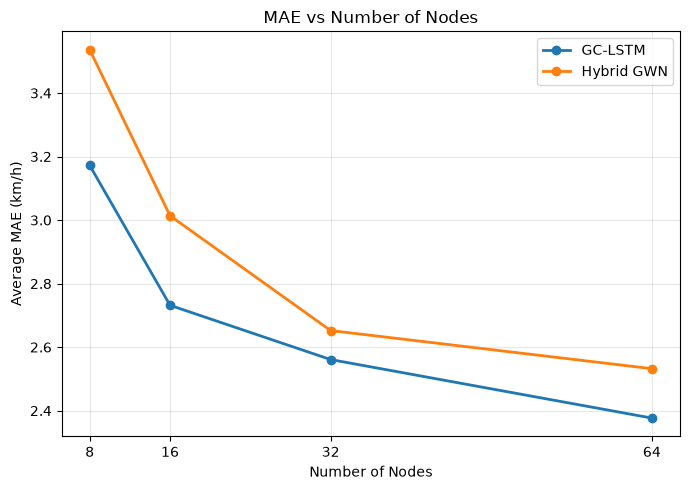

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/plots/scalability_mae.png


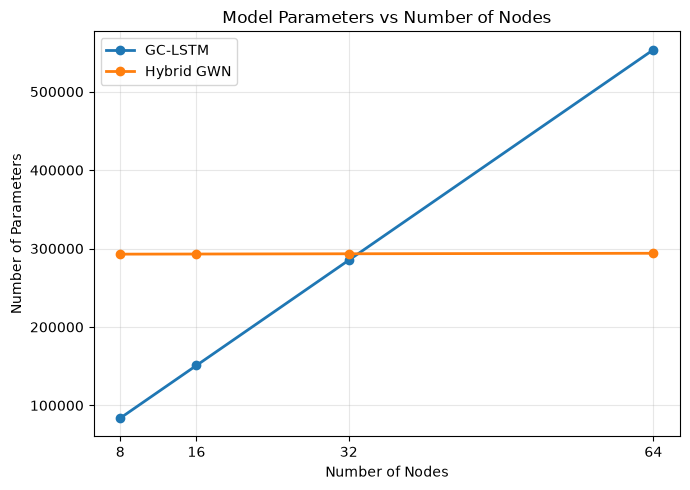

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/plots/scalability_parameters.png


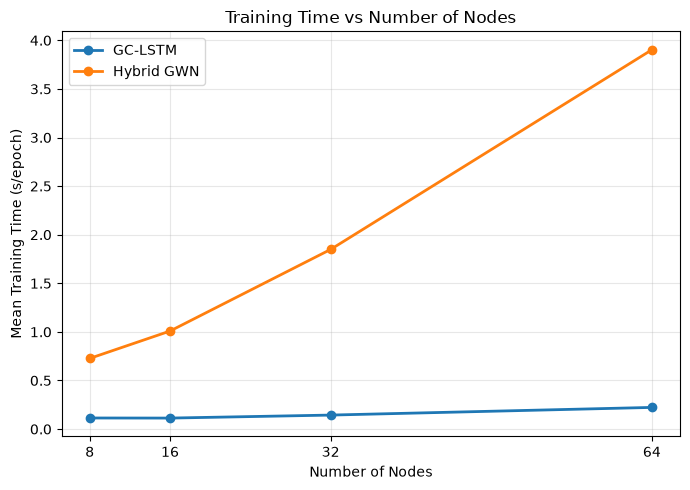

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/plots/scalability_training_time.png


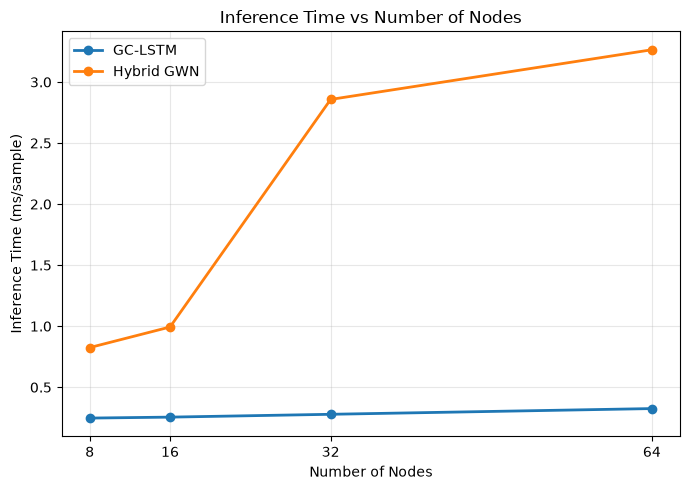

Saved: /Users/aisha/Documents/SKRIPSI 2026/SEMINAR 2026/tomtom-stgnn-agent/outputs/final_64/scalability/plots/scalability_inference_time.png


In [20]:
# ============================================================
# SCALABILITY VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

plot_dir = OUTPUT_DIR / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

models = ["GC-LSTM", "Hybrid GWN"]


def plot_scalability(metric, ylabel, title, filename):
    plt.figure(figsize=(7, 5))

    for model_name in models:
        subset = df_summary[df_summary["model"] == model_name].sort_values("num_nodes")

        plt.plot(subset["num_nodes"], subset[metric], marker="o", linewidth=2, label=model_name)

    plt.xticks([8, 16, 32, 64])

    plt.xlabel("Number of Nodes")

    plt.ylabel(ylabel)

    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    path = plot_dir / filename

    plt.savefig(path, dpi=300, bbox_inches="tight")

    plt.show()

    print("Saved:", path)


# 1. MAE
plot_scalability(
    metric="avg_mae_kmh",
    ylabel="Average MAE (km/h)",
    title="MAE vs Number of Nodes",
    filename="scalability_mae.png",
)


# 2. Parameters
plot_scalability(
    metric="parameters",
    ylabel="Number of Parameters",
    title="Model Parameters vs Number of Nodes",
    filename="scalability_parameters.png",
)


# 3. Training time
plot_scalability(
    metric="mean_sec_per_epoch",
    ylabel="Mean Training Time (s/epoch)",
    title="Training Time vs Number of Nodes",
    filename="scalability_training_time.png",
)


# 4. Inference time
plot_scalability(
    metric="inference_ms_per_sample",
    ylabel="Inference Time (ms/sample)",
    title="Inference Time vs Number of Nodes",
    filename="scalability_inference_time.png",
)

## 17. Scalability Analysis

Berdasarkan eksperimen pada ukuran graph **8, 16, 32, dan 64 node**, Hybrid Graph WaveNet dan GC-LSTM menunjukkan karakteristik scalability yang berbeda.

### Predictive Performance

Rata-rata MAE GC-LSTM berubah dari **3.1721 km/h pada 8 node menjadi 2.3767 km/h pada 64 node**, sedangkan Hybrid Graph WaveNet berubah dari **3.5363 km/h menjadi 2.5322 km/h**. Pada konfigurasi subset yang diuji, tidak terlihat degradasi error ketika jumlah node bertambah.

Namun, penurunan MAE **tidak dapat langsung diartikan bahwa penambahan node menyebabkan peningkatan akurasi**, karena setiap ukuran graph memiliki populasi corridor yang berbeda. Oleh karena itu, MAE dan RMSE digunakan sebagai indikator perubahan predictive performance pada setiap ukuran graph, bukan sebagai bukti hubungan kausal antara jumlah node dan akurasi.

### Model Size

GC-LSTM mengalami peningkatan jumlah parameter yang cukup besar, dari **83,800 parameter pada 8 node menjadi 553,472 parameter pada 64 node**. Hal ini terjadi karena representasi seluruh node di-*flatten* sebelum diproses oleh Long Short-Term Memory (LSTM), sehingga bertambahnya jumlah node meningkatkan dimensi input LSTM.

Sebaliknya, jumlah parameter Hybrid Graph WaveNet relatif stabil, dari **292,835 menjadi 293,955 parameter**. Mayoritas parameter Graph WaveNet tidak bergantung langsung pada jumlah node, sedangkan pertambahan parameter terutama berasal dari komponen adaptive node embedding.

### Training Time

Rata-rata training time GC-LSTM meningkat dari **0.1141 s/epoch menjadi 0.2230 s/epoch**, sedangkan Hybrid Graph WaveNet meningkat dari **0.7272 s/epoch menjadi 3.9032 s/epoch**.

Total training time tidak digunakan sebagai indikator utama scalability karena jumlah epoch setiap eksperimen berbeda akibat penggunaan *early stopping*. Oleh karena itu, **mean training time per epoch** lebih representatif untuk membandingkan computational cost antar ukuran graph.

### Inference Time

Inference time GC-LSTM meningkat dari **0.2475 ms/sample pada 8 node menjadi 0.3254 ms/sample pada 64 node**. Pada Hybrid Graph WaveNet, inference time meningkat dari **0.8251 ms/sample menjadi 3.2644 ms/sample**.

Hasil ini menunjukkan bahwa meskipun jumlah parameter Hybrid Graph WaveNet relatif stabil ketika jumlah node bertambah, biaya komputasinya tetap meningkat karena operasi graph dan diffusion dilakukan pada graph yang semakin besar.

### Conclusion

Eksperimen menunjukkan adanya perbedaan bentuk scalability antara kedua arsitektur. **Hybrid Graph WaveNet memiliki pertumbuhan jumlah parameter yang jauh lebih kecil terhadap peningkatan jumlah node**, sedangkan **GC-LSTM memiliki training dan inference time yang lebih rendah pada implementasi dan hardware pengujian ini**.

Dengan demikian, scalability model tidak cukup dinilai hanya berdasarkan jumlah parameter. Evaluasi juga perlu mempertimbangkan **predictive performance, training time, dan inference time** ketika ukuran graph bertambah.

Sebagai validasi tambahan, fixed graph pada eksperimen 64-node telah dibandingkan dengan graph Final64 asli. Keduanya memiliki **256 directed edges**, tanpa perbedaan adjacency, serta memiliki forward dan reverse support yang identik. Hal ini memastikan bahwa graph 64-node pada scalability experiment konsisten dengan fixed graph Final64 yang digunakan pada eksperimen utama.